In [1]:
%pip install pandas matplotlib seaborn numpy
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')

Note: you may need to restart the kernel to use updated packages.


# 01. What data do we have?

Start here. A Grand Slam is one of the four biggest tennis tournaments: the Australian Open, the French Open (also called Roland Garros), Wimbledon, and the US Open. This project uses the original TennisAnalytics repo files, which cover only men's singles at those four Slams, from 2000 to 2019. Later notebooks add a wider tour supplement, but this chapter first checks exactly what the original files contain, and what they do not contain.

In [2]:
import os
PROC = os.path.join('..', 'data', 'processed')
CH = os.path.join('..', 'charts')
os.makedirs(CH, exist_ok=True)

## The three original files

Match.csv has one row per match, with round, date, tournament, year, and match length. Stats.csv has two rows per match, one per player, with aces, double faults, break points, serve numbers, and rank. Player.csv is a long player list with name, playing hand, country, and birthday. It lists far more players than ever appear in these Slam matches, so do not be surprised by its size.

In [3]:
match = pd.read_csv('../data/raw/Match.csv')
player = pd.read_csv('../data/raw/Player.csv')
stats = pd.read_csv('../data/raw/Stats.csv')
print('Match rows, columns:', match.shape, list(match.columns))
print('Player rows, columns:', player.shape, list(player.columns))
print('Stats rows, columns:', stats.shape, list(stats.columns))
print('Years:', sorted(match.year.unique()))
print('Tournaments:', sorted(match.tournament.unique()))
print('Rounds:', match['round'].value_counts().to_dict())

Match rows, columns: (10160, 9) ['match_id', 'round', 'date', 'avg_minutes_game', 'avg_seconds_point', 'avg_minutes_set', 'tournament', 'year', 'match_minutes']
Player rows, columns: (53666, 5) ['player_id', 'name', 'hand', 'country', 'birthday']
Stats rows, columns: (20240, 24) ['match_id', 'player_id', 'pts', 'rank', 'winner', 'sets', '1', '2', '3', '4', '5', 'avg_odds', 'max_odds', 'total_pts', 'service_pts', 'return_pts', 'aces', 'bp_saved', 'bp_faced', 'first_serve_rtn_won', 'second_serve_rtn_won', 'first_serve_in', 'dbl_faults', 'first_serve_per']
Years: [np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
Tournaments: ['Australian Open', 'French Open', 'US Open', 'Wimbledon']
Rounds: {'1st Round': 5120, '2nd Round':

## Coverage, and one honest gap

There are 10,160 rows in Match.csv, which is 127 matches times 4 Slams times 20 years. Stats.csv has 20,240 player rows, which is 2 players times 10,120 matches. That means 40 matches in Match.csv have no Stats rows at all. Those 40 also have blank match length and timing columns. They are kept out of every serve and win rate number in this project, and they are counted here so the gap is visible, not hidden.

In [4]:
in_stats = set(stats.match_id)
missing = match[~match.match_id.isin(in_stats)]
print('Matches in Match.csv:', len(match))
print('Matches with Stats rows:', len(in_stats))
print('Matches missing from Stats.csv:', len(missing))
print(missing.groupby(['year', 'tournament']).size())
print('Date range:', match.date.min(), 'to', match.date.max())
print('Players in Player.csv:', len(player), 'from', player.country.nunique(), 'country codes')

Matches in Match.csv: 10160
Matches with Stats rows: 10120
Matches missing from Stats.csv: 40
year  tournament     
2003  Australian Open    1
2004  US Open            1
2005  French Open        2
      US Open            1
2006  Australian Open    1
2007  US Open            2
      Wimbledon          1
2009  Australian Open    2
      US Open            1
      Wimbledon          1
2010  Australian Open    1
      Wimbledon          1
2011  French Open        1
2012  Australian Open    1
      US Open            1
2013  French Open        1
      Wimbledon          2
2014  Australian Open    1
      US Open            2
2015  French Open        2
      Wimbledon          1
2016  French Open        1
      US Open            1
2017  Australian Open    1
2019  Australian Open    8
      US Open            2
dtype: int64
Date range: 2000-01-17 to 2019-12-07
Players in Player.csv: 53666 from 204 country codes


## Chart: matches by round. Every Slam draw has the same shape.

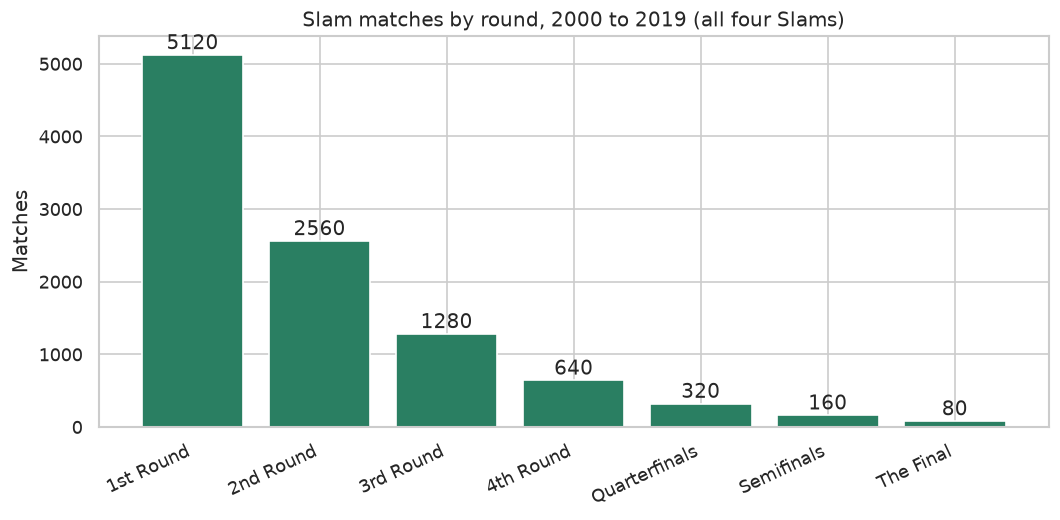

In [5]:
counts = match['round'].value_counts()
order = ['1st Round', '2nd Round', '3rd Round', '4th Round', 'Quarterfinals', 'Semifinals', 'The Final']
vals = [counts[r] for r in order]
plt.figure(figsize=(9, 4.5)); plt.bar(order, vals, color='#2a7f62')
plt.title('Slam matches by round, 2000 to 2019 (all four Slams)'); plt.ylabel('Matches'); plt.xticks(rotation=25, ha='right')
for i, v in enumerate(vals): plt.text(i, v + 80, str(v), ha='center')
plt.tight_layout(); plt.savefig(f'{CH}/01_matches_by_round.png'); plt.show()

## What is missing, in plain words

No surface column. Surface is mapped from tournament name in the processed data: Australian Open and US Open are Hard, French Open is Clay, Wimbledon is Grass. No women's matches. No matches after 2019. No seed column, only a rank number at match time. Notebook 06 fills the recent years and the women's gap with the Sackmann supplement, and every later claim says which data it uses.

In [6]:
print('Original repo: mens Slam singles only, 2000 to 2019.')
print('Supplement in notebook 06: Sackmann tour data, ATP and WTA, 2000 to 2024.')
print('Surface in original data is mapped from tournament name, not printed in the file.')

Original repo: mens Slam singles only, 2000 to 2019.
Supplement in notebook 06: Sackmann tour data, ATP and WTA, 2000 to 2024.
Surface in original data is mapped from tournament name, not printed in the file.
